# Etapa 5 - Clasificación automática de productos mediante NLP y Machine Learning

**Introducción**  
En las etapas anteriores se construyó una base de productos comunes entre Carrefour y DIA, se analizaron sus precios y se definió una taxonomía comercial propia para organizar los productos en categorías. Debido a que los datos originales no cuentan con una clasificación comercial suficientemente detallada y homogénea para los objetivos del proyecto, se realizó un primer etiquetado manual de productos, que constituye la base inicial para desarrollar y evaluar modelos de clasificación automática.

En esta etapa se aplicarán técnicas de **Procesamiento del Lenguaje Natural (NLP)** y **Machine Learning** para entrenar modelos capaces de asignar una categoría comercial a cada producto a partir de su descripción textual. Se compararán cinco enfoques de distinta complejidad: tres variantes de TF-IDF con clasificadores lineales (regresión logística, SVM lineal y SVM con n-gramas de palabras y caracteres), una con reducción dimensional (LSA) y una representación semántica densa combinada con un modelo basado en árboles, y se seleccionará el que ofrezca la mejor relación costo/beneficio para el proyecto.

**Objetivo general**  
Desarrollar y evaluar modelos de clasificación automática de productos que permitan asignar categorías comerciales de manera consistente, reduciendo la necesidad de etiquetado manual y preparando los datos para los análisis comparativos posteriores.

**Objetivos específicos**  
1. Preparar y validar el conjunto de productos etiquetados manualmente.  
2. Analizar la distribución de las categorías y la calidad de las etiquetas disponibles.  
3. Preprocesar las descripciones de los productos para utilizarlas como variables de entrada.  
4. Comparar cinco enfoques de modelado: TF-IDF + regresión logística, TF-IDF + SVM lineal, Doc2Vec + XGBoost, TF-IDF + LSA + SVM lineal y TF-IDF (palabras + caracteres) + SVM lineal.  
5. Evaluar los resultados mediante métricas adecuadas para clasificación multiclase desbalanceada (macro F1 como métrica principal).  
6. Seleccionar el modelo con mejor relación costo/beneficio.  
7. Aplicar el modelo ganador a los productos que aún no tienen categoría asignada.  

**Criterios metodológicos**  
- La **métrica principal** es el **macro F1**, dado el desbalance entre categorías.  
- Se reportan también **accuracy** y **weighted F1** como complemento.  
- Todos los modelos se evalúan sobre el **mismo split** de train/test, con `random_state=42` y `stratify=y` para asegurar comparabilidad.  
- La vectorización se ajusta **solo con el train set** para evitar data leakage.  
- Se describe de forma cualitativa el costo computacional de cada enfoque.
- La comparación en test se complementa con validación cruzada estratificada repetida (5 folds × 3 repeticiones), dado el tamaño reducido del test.  

**Resultado esperado**  
Un flujo de trabajo reproducible para la clasificación automática de productos, una evaluación objetiva de cinco enfoques de complejidad creciente, y una primera categorización automática de los productos sin etiqueta manual.

## 1. Carga de datos

En este apartado se carga el dataset con el universo de productos etiquetados manualmente en la etapa anterior. Los datos provienen del universo depurado de siete provincias e incluyen el identificador del producto, los precios medios en ambas cadenas, las descripciones comerciales, la marca y la categoría asignada manualmente.

La categoría es la variable objetivo (`target`) que el modelo deberá aprender a predecir. Los productos sin categoría se conservarán para aplicarle el modelo en la última sección del notebook.

La carga se realiza en formato Excel para preservar la estructura del etiquetado manual tal como fue entregada.

In [37]:
# Importaciones y configuración inicial del entorno
import warnings
warnings.filterwarnings('ignore')

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42

In [38]:
# Cargamos el dataset con los productos etiquetados manualmente y los pendientes de clasificación
productos_etiquetados_parcialmente = pd.read_excel("../data/processed/productos_etiquetados_parcialmente.xlsx", sheet_name="Sheet1")

productos_etiquetados_parcialmente.head(5)

,id_producto,precio_medio_carrefour,precio_medio_dia,descripcion_dia,descripcion_carrefour,productos_marca,categoria
0,40084107,2875.50,2793.33,HUEVO DE CHOCOLATE,HUEVO CHOCOLATE SORPRESA CELESTE KINDER X 20 GRS,KINDER,ALIMENTOS
1,42277057,7872.42,6455.00,CREM FACIAL CUID NUT,CREMA FACIAL CUIDADO NUTRITIVO NIVEA CARE X 100CC,NIVEA,NaN
2,75079437,18265.21,12750.00,ANTITRANS CREM WOMEN,ANTITRANSP FEM CREMA CLINICAL SOFT DOVE X 58GRS,DOVE,NaN
3,75082734,7906.62,8037.19,ANTITRANS ORIG BARRA,ANTITRANSPIRANTE BARRA ORIGINAL DOVE X 53 GR,DOVE,NaN
4,75083694,8677.08,8718.77,DEO BLUE LAVEN BARRA,DESODORANTE STICK BLUE LAVENDER AXE X 58 GRM,AXE,PERFUMERIA Y LIMPIEZA


## 2. Validación del conjunto etiquetado

Antes de avanzar hacia el modelado, se verifica la integridad del dataset: cantidad de registros, tipos de datos y presencia de valores nulos.

El objetivo de esta sección es confirmar que el archivo se cargó correctamente y detectar cuántos productos quedan pendientes de categorización, ya que esa información se utilizará en la etapa final de aplicación del modelo.

In [39]:
productos_etiquetados_parcialmente.info()
print("\nValores nulos por columna:")
print(productos_etiquetados_parcialmente.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2220 entries, 0 to 2219
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_producto             2220 non-null   int64  
 1   precio_medio_carrefour  2220 non-null   float64
 2   precio_medio_dia        2220 non-null   float64
 3   descripcion_dia         2220 non-null   str    
 4   descripcion_carrefour   2220 non-null   str    
 5   productos_marca         2220 non-null   str    
 6   categoria               400 non-null    str    
dtypes: float64(2), int64(1), str(4)
memory usage: 274.1 KB

Valores nulos por columna:
id_producto                  0
precio_medio_carrefour       0
precio_medio_dia             0
descripcion_dia              0
descripcion_carrefour        0
productos_marca              0
categoria                 1820
dtype: int64


## 3. Análisis de la distribución de las categorías

Se analiza la distribución de las categorías disponibles para detectar posibles desbalances que condicionen las decisiones de modelado.

El desbalance es un factor crítico en clasificación multiclase: si algunas categorías tienen muy pocas observaciones, el modelo tenderá a ignorarlas en favor de las mayoritarias. Este análisis guiará la elección de parámetros como `class_weight='balanced'` en los modelos lineales.

Se presentan tanto cantidades absolutas como porcentajes para dimensionar el problema.

In [40]:
# Normalizamos etiquetas y detectamos cuáles tienen categoría asignada
categorias = productos_etiquetados_parcialmente['categoria'].astype('string').str.strip()
tiene_categoria = categorias.notna() & categorias.ne('')

dist = categorias[tiene_categoria].value_counts().sort_index()
print("Distribución de categorías (cantidad):")
print(dist)

porcentajes = (dist / dist.sum() * 100).round(2)
print("\nParticipación porcentual:")
print(porcentajes)

Distribución de categorías (cantidad):
categoria
ALIMENTOS                184
BEBIDAS                   62
MASCOTAS                  27
OTROS                     12
PERFUMERIA Y LIMPIEZA    115
Name: count, dtype: int64[pyarrow]

Participación porcentual:
categoria
ALIMENTOS                 46.0
BEBIDAS                   15.5
MASCOTAS                  6.75
OTROS                      3.0
PERFUMERIA Y LIMPIEZA    28.75
Name: count, dtype: double[pyarrow]


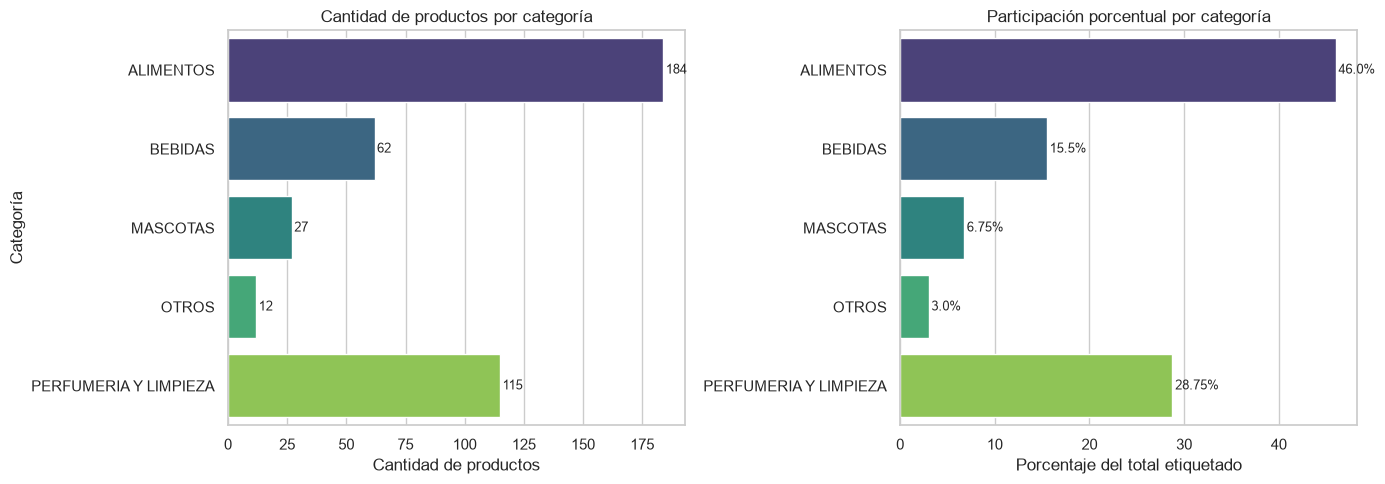

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(y=dist.index, x=dist.values, hue=dist.index,
            legend=False, palette="viridis", ax=axes[0])
axes[0].set_title("Cantidad de productos por categoría")
axes[0].set_xlabel("Cantidad de productos")
axes[0].set_ylabel("Categoría")
for i, v in enumerate(dist.values):
    axes[0].text(v + 1, i, f"{v}", va='center', fontsize=9)

sns.barplot(y=porcentajes.index, x=porcentajes.values, hue=porcentajes.index,
            legend=False, palette="viridis", ax=axes[1])
axes[1].set_title("Participación porcentual por categoría")
axes[1].set_xlabel("Porcentaje del total etiquetado")
axes[1].set_ylabel("")
for i, v in enumerate(porcentajes.values):
    axes[1].text(v + 0.3, i, f"{v}%", va='center', fontsize=9)

plt.tight_layout()
plt.show()

**Lectura de la distribución**

Se observa un desbalance marcado: **ALIMENTOS** concentra casi la mitad del universo etiquetado, mientras que **OTROS** y **MASCOTAS** representan, en conjunto, menos del 10%. Esta diferencia condiciona el modelado porque:

- Un modelo sin balanceo tenderá a predecir correctamente las categorías mayoritarias y a ignorar las minoritarias.
- Las métricas globales (accuracy) pueden ser altas incluso cuando el modelo falla sistemáticamente en las categorías con pocas muestras.
- Por ese motivo, la métrica principal del proyecto será el **macro F1**, que promedia el desempeño de todas las categorías por igual, independientemente de su tamaño.

Cabe aclarar que el conjunto etiquetado no es una muestra aleatoria del universo: se priorizó incluir más ejemplos de MASCOTAS y OTROS, por lo que el desbalance real del universo completo es probablemente mayor al que muestra este análisis.

## 4. Construcción del corpus de entrenamiento

Se filtra el dataset para quedarse únicamente con los productos que tienen categoría asignada. Sobre ese subconjunto se construye el texto de entrada del modelo combinando tres fuentes de información:

- la descripción comercial de Carrefour,
- la descripción comercial de DIA,
- la marca del producto.

La combinación aumenta la cantidad de palabras disponibles para el modelo y aporta señales complementarias (por ejemplo, la marca puede ser un indicio fuerte de la categoría de un producto de cuidado personal o limpieza).

In [42]:
# Filtramos productos con categoría asignada y construimos el texto combinado
productos_train = productos_etiquetados_parcialmente[
    productos_etiquetados_parcialmente['categoria'].notna()
].copy()

productos_train['texto_combinado'] = (
    productos_train['descripcion_carrefour'].fillna('') + ' ' +
    productos_train['descripcion_dia'].fillna('') + ' ' +
    productos_train['productos_marca'].fillna('')
)

productos_train = productos_train[productos_train['texto_combinado'].str.strip() != '']

print(f"Productos con categoría asignada y texto válido: {len(productos_train)}")

Productos con categoría asignada y texto válido: 400


## 5. División train/test

Se divide el corpus en un conjunto de entrenamiento (80%) y un conjunto de prueba (20%). La división se realiza con **estratificación** por categoría para preservar la proporción original de clases en ambos subconjuntos. Sin estratificación, en un dataset pequeño y desbalanceado, algunas categorías podrían quedar subrepresentadas o ausentes en alguno de los conjuntos.

Se fija `random_state=42` para asegurar que cualquier persona que ejecute el notebook obtenga exactamente la misma partición.

In [43]:
X = productos_train['texto_combinado']
y = productos_train['categoria']

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Textos de entrenamiento: {len(X_train)}")
print(f"Textos de test: {len(X_test)}")
print("\nDistribución en train:")
print(y_train.value_counts().sort_index())
print("\nDistribución en test:")
print(y_test.value_counts().sort_index())

Textos de entrenamiento: 320
Textos de test: 80

Distribución en train:
categoria
ALIMENTOS                147
BEBIDAS                   50
MASCOTAS                  22
OTROS                      9
PERFUMERIA Y LIMPIEZA     92
Name: count, dtype: int64

Distribución en test:
categoria
ALIMENTOS                37
BEBIDAS                  12
MASCOTAS                  5
OTROS                     3
PERFUMERIA Y LIMPIEZA    23
Name: count, dtype: int64


## 6. Vectorización TF-IDF

Se transforma el texto en una representación numérica mediante **TF-IDF** (Term Frequency - Inverse Document Frequency). Esta técnica asigna pesos a cada término en función de su frecuencia en el documento y de su rareza en el corpus, reduciendo la importancia de palabras muy frecuentes que no aportan información discriminante.

Se configuran tres parámetros clave:

- `max_features=20000`: limita el vocabulario para controlar la dimensión del espacio vectorial.
- `ngram_range=(1, 3)`: captura tanto unigramas como bigramas y trigramas, permitiendo representar frases como "crema facial" o "limpiador de pisos".
- `min_df=2`: ignora términos que aparecen en menos de 2 documentos, filtrando ruido y errores de tipeo.

El ajuste se realiza **solo sobre `X_train`** para evitar data leakage: el vocabulario y los pesos IDF se calculan exclusivamente con la información del conjunto de entrenamiento. El conjunto de test se transforma aplicando esa misma configuración.

In [44]:
vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 3), min_df=2, lowercase=True)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"Dimensión de X_train_tfidf: {X_train_tfidf.shape}")
print(f"Dimensión de X_test_tfidf:  {X_test_tfidf.shape}")

Dimensión de X_train_tfidf: (320, 789)
Dimensión de X_test_tfidf:  (80, 789)


### Funciones auxiliares para la evaluación de modelos

Se importan desde `src/metricas_ml.py` dos funciones reutilizables:

- `plot_confusion_matrix()`: grafica la matriz de confusión como un mapa de calor, permitiendo identificar las categorías que el modelo confunde.
- `resumen_metricas()`: calcula Accuracy, Macro F1 y Weighted F1 para resumir el desempeño del modelo.

Estas funciones permiten reutilizar los mismos criterios de evaluación en los distintos modelos analizados.

In [45]:
import sys
from pathlib import Path

# Agregamos la raíz del proyecto a las rutas de Python
sys.path.insert(0, str(Path.cwd().parent))

# Importamos las funciones auxiliares
from src.metricas_ml import plot_confusion_matrix, resumen_metricas

## 7. Modelo 1, Línea base: TF-IDF + LogisticRegression

El primer modelo combina la representación TF-IDF con **regresión logística multiclase**. Es el enfoque más simple y rápido de entrenar, y sirve como **línea base** para medir el aporte de los enfoques más complejos.

Se configura `class_weight='balanced'` para que el clasificador ajuste automáticamente los pesos de cada categoría de forma inversamente proporcional a su frecuencia, compensando el desbalance detectado en el apartado 3.

**Costo:** bajo. Entrena en fracciones de segundo sobre este volumen de datos y no requiere GPU.

In [46]:
modelo_1 = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
modelo_1.fit(X_train_tfidf, y_train)

y_pred_1 = modelo_1.predict(X_test_tfidf)

print("=== Modelo 1: TF-IDF + LogisticRegression (balanced) ===")
print(classification_report(y_test, y_pred_1))

=== Modelo 1: TF-IDF + LogisticRegression (balanced) ===
                       precision    recall  f1-score   support

            ALIMENTOS       0.95      0.97      0.96        37
              BEBIDAS       0.80      1.00      0.89        12
             MASCOTAS       1.00      1.00      1.00         5
                OTROS       1.00      0.67      0.80         3
PERFUMERIA Y LIMPIEZA       0.95      0.83      0.88        23

             accuracy                           0.93        80
            macro avg       0.94      0.89      0.91        80
         weighted avg       0.93      0.93      0.92        80



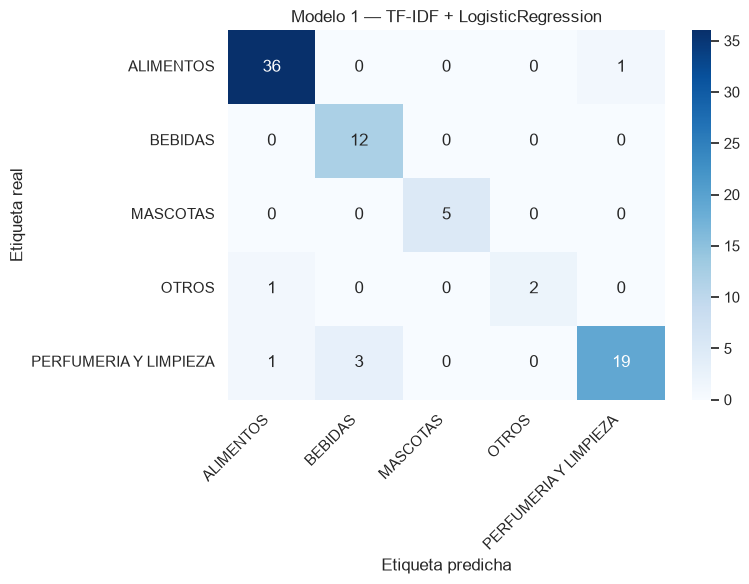

In [47]:
cm_1 = confusion_matrix(y_test, y_pred_1, labels=modelo_1.classes_)
plot_confusion_matrix(cm_1, modelo_1.classes_, 'Modelo 1 — TF-IDF + LogisticRegression')

**Comentario del Modelo 1**

El modelo alcanza un accuracy de 0,93 (74 de 80 productos del test) y un macro F1 de 0,91. ALIMENTOS (F1 0,96), BEBIDAS (0,89) y MASCOTAS (1,00) quedan en valores altos.

Los 6 errores se distribuyen así: 3 productos de PERFUMERIA Y LIMPIEZA predichos como BEBIDAS, 1 de PERFUMERIA Y LIMPIEZA predicho como ALIMENTOS, 1 de ALIMENTOS predicho como PERFUMERIA Y LIMPIEZA y 1 de OTROS predicho como ALIMENTOS. La confusión principal no es entre ALIMENTOS y PERFUMERIA Y LIMPIEZA, sino que productos líquidos de limpieza y cuidado se predicen como bebidas, lo que baja la precisión de BEBIDAS a 0,80. Los tres vienen con el volumen expresado en “CC”, un término que probablemente comparten con las bebidas (hipótesis que no se verificó en este notebook).

La categoría OTROS, con solo 3 observaciones en el test, es la más sensible: cada acierto o error mueve su recall 33 puntos porcentuales (aquí acertó 2 de 3, recall 0,67). Como el macro F1 pondera todas las categorías por igual, esa única categoría explica casi toda la diferencia de macro F1 entre los modelos.

## 8. Modelo 2, Lineal robusto: TF-IDF + LinearSVC

El segundo modelo reemplaza la regresión logística por un **SVM lineal** (`LinearSVC`). En clasificación de texto, los SVM lineales suelen rendir igual o mejor que la regresión logística, especialmente cuando el número de características supera ampliamente al de observaciones.

Se mantiene `class_weight='balanced'` para preservar el manejo del desbalance. Se aumenta `max_iter` a 5000 para asegurar la convergencia del optimizador.

**Costo:** bajo, similar al Modelo 1. `LinearSVC` no devuelve probabilidades calibradas (a diferencia de la regresión logística), pero para clasificación directa es igualmente válido.

In [48]:
modelo_2 = LinearSVC(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE)
modelo_2.fit(X_train_tfidf, y_train)

y_pred_2 = modelo_2.predict(X_test_tfidf)

print("=== Modelo 2: TF-IDF + LinearSVC (balanced) ===")
print(classification_report(y_test, y_pred_2))

=== Modelo 2: TF-IDF + LinearSVC (balanced) ===
                       precision    recall  f1-score   support

            ALIMENTOS       0.92      0.97      0.95        37
              BEBIDAS       0.86      1.00      0.92        12
             MASCOTAS       1.00      1.00      1.00         5
                OTROS       1.00      0.33      0.50         3
PERFUMERIA Y LIMPIEZA       0.95      0.87      0.91        23

             accuracy                           0.93        80
            macro avg       0.95      0.84      0.86        80
         weighted avg       0.93      0.93      0.92        80



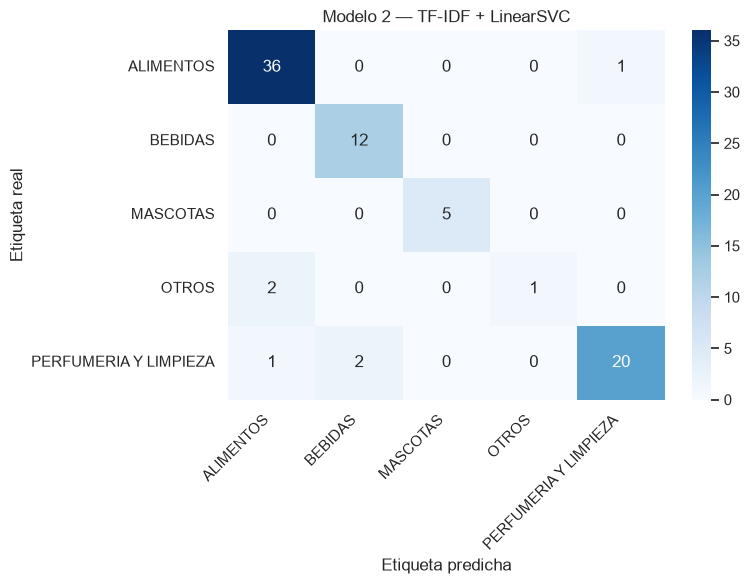

In [49]:
cm_2 = confusion_matrix(y_test, y_pred_2, labels=modelo_2.classes_)
plot_confusion_matrix(cm_2, modelo_2.classes_, 'Modelo 2 — TF-IDF + LinearSVC')

**Comentario del Modelo 2**

El SVM lineal obtiene exactamente el mismo accuracy que el Modelo 1 (0,93, los mismos 74 aciertos), pero un macro F1 menor (0,86 contra 0,91). La diferencia viene de la categoría OTROS: el Modelo 1 acertó 2 de los 3 productos (recall 0,67) y el Modelo 2 solo 1 de 3 (recall 0,33). En el resto de las categorías el desempeño es equivalente. Es decir, la diferencia de macro F1 entre ambos depende de un solo producto de un test de 80.

Este resultado ilustra un punto metodológico importante: **no existe un modelo universalmente mejor**. Un algoritmo que en benchmarks generales rinde mejor puede quedar por debajo en un dataset pequeño y desbalanceado como el de este proyecto, simplemente porque la estimación de su desempeño tiene alta varianza.

## 9. Modelo 3, Representación semántica: Doc2Vec + XGBoost

El tercer modelo introduce un cambio de representación: en lugar de TF-IDF, se entrena un **Doc2Vec** que aprende un vector denso por producto, capturando no solo la frecuencia de palabras sino también el contexto en el que aparecen.

Sobre esos vectores se entrena un XGBoost (árboles con boosting), un enfoque más costoso computacionalmente que los modelos lineales. Este modelo requiere los paquetes gensim y xgboost. A diferencia de los Modelos 1, 2 y 4, no incorpora balanceo de clases, por lo que su comparación con los anteriores no es del todo homogénea.

**Reproducibilidad:** debido al componente aleatorio de Doc2Vec, se fijaron las semillas de NumPy y Gensim, se estableció `PYTHONHASHSEED=42` antes de iniciar el entorno de ejecución y se utilizó un único hilo de entrenamiento (`workers=1`). Se verificó que las métricas fueran consistentes en dos ejecuciones independientes del notebook bajo la misma configuración.

**Costo:** esperablemente medio-alto. No se midieron tiempos de entrenamiento en este notebook. La ventaja esperada es una mejor captura del contexto semántico, especialmente en descripciones muy cortas.


In [50]:
import os

print(os.environ.get("PYTHONHASHSEED", "No configurada"))

42


In [51]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

# Función que tokeniza a minúsculas y extrae solo secuencias alfanuméricas.
def tokenize_simple(texto):    
    return re.findall(r'\b[a-z0-9]+\b', texto.lower())


train_tagged = [
    TaggedDocument(words=tokenize_simple(doc), tags=[i])
    for i, doc in enumerate(X_train)
]

np.random.seed(RANDOM_STATE)
doc2vec_model = Doc2Vec(documents=train_tagged, vector_size=180, window=5, min_count=2, workers=1, epochs=60, seed=RANDOM_STATE)

# Vectores de entrenamiento (los ya aprendidos)
X_train_d2v = np.array([
    doc2vec_model.dv[i] for i in range(len(X_train))
])

# Vectores de test (se infieren con el modelo ya entrenado)
doc2vec_model.random.seed(RANDOM_STATE)
X_test_d2v = np.array([
    doc2vec_model.infer_vector(tokenize_simple(doc), epochs=60)
    for doc in X_test
])

print(f"Dimensión de X_train_d2v: {X_train_d2v.shape}")
print(f"Dimensión de X_test_d2v:  {X_test_d2v.shape}")

Dimensión de X_train_d2v: (320, 180)
Dimensión de X_test_d2v:  (80, 180)


In [52]:
# Codificamos etiquetas a enteros (requerido por XGBoost)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

from xgboost import XGBClassifier

modelo_3 = XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.1, random_state=RANDOM_STATE, eval_metric='mlogloss')

nombre_modelo_3 = 'XGBoost'

# Entrenamiento
modelo_3.fit(X_train_d2v, y_train_enc)

# Predicción (volvemos a etiquetas originales)
y_pred_3 = le.inverse_transform(modelo_3.predict(X_test_d2v))

print(f"\n=== Modelo 3: Doc2Vec + {nombre_modelo_3} ===")
print(classification_report(y_test, y_pred_3))



=== Modelo 3: Doc2Vec + XGBoost ===
                       precision    recall  f1-score   support

            ALIMENTOS       0.79      0.89      0.84        37
              BEBIDAS       0.69      0.75      0.72        12
             MASCOTAS       0.62      1.00      0.77         5
                OTROS       1.00      0.33      0.50         3
PERFUMERIA Y LIMPIEZA       0.88      0.61      0.72        23

             accuracy                           0.78        80
            macro avg       0.80      0.72      0.71        80
         weighted avg       0.80      0.78      0.77        80



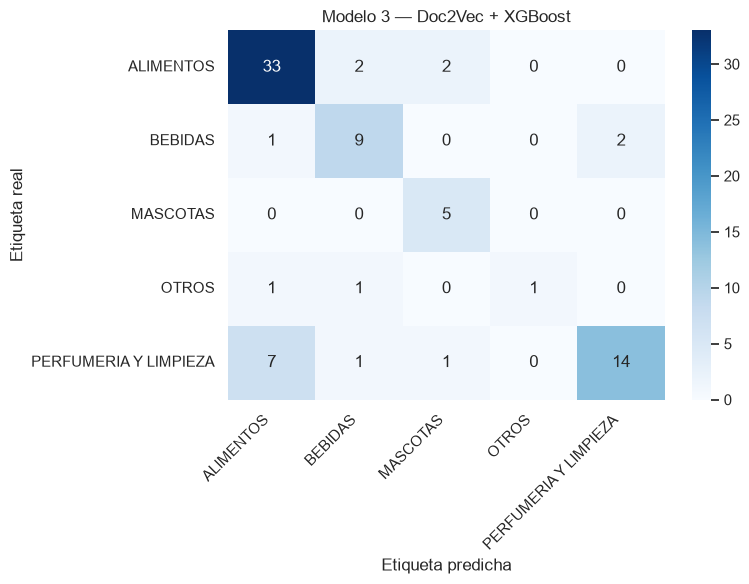

In [53]:
cm_3 = confusion_matrix(y_test, y_pred_3, labels=le.classes_)
plot_confusion_matrix(cm_3, le.classes_, f'Modelo 3 — Doc2Vec + {nombre_modelo_3}')

### Comentario del Modelo 3

El modelo obtiene un **accuracy de 0,78 y un Macro F1 de 0,71**, mostrando un rendimiento moderado en la clasificación de productos.

Presenta buenos resultados en ALIMENTOS (recall de 0,89), BEBIDAS (0,75) y MASCOTAS (1,00). Sin embargo, encuentra mayores dificultades en OTROS (0,33, con solo 1 de 3 productos correctamente clasificados) y PERFUMERIA Y LIMPIEZA (0,61).

Una explicación plausible de estas limitaciones es el tamaño reducido del corpus de entrenamiento (320 documentos), que puede dificultar el aprendizaje de representaciones vectoriales eficaces. Otros factores que pueden influir son el desbalance entre categorías y las diferencias entre los vectores de entrenamiento, aprendidos directamente, y los de prueba, obtenidos mediante inferencia.

## 10. Modelo 4, Reducción dimensional: TF-IDF + LSA + LinearSVC

El cuarto modelo combina dos ideas ya exploradas por separado: la representación **TF-IDF** (que captura señal léxica directa) y un clasificador **SVM lineal** (que rinde bien en texto de alta dimensionalidad). La diferencia es que ahora se interpone una etapa de **reducción dimensional mediante LSA (Latent Semantic Analysis)**, implementada con `TruncatedSVD` de scikit-learn.

**¿Qué hace LSA?** LSA aplica una descomposición en valores singulares (SVD) sobre la matriz TF-IDF para proyectar los documentos en un espacio de menor dimensión (en este caso, 100 componentes) donde los ejes representan **temas latentes** en lugar de palabras individuales. El resultado es una representación más compacta que puede capturar relaciones semánticas entre términos que TF-IDF crudo no ve (por ejemplo, podría agrupar ‘crema’ y ‘loción’ en un mismo componente), sin el costo de entrenar una red neuronal como Doc2Vec.

**¿Por qué probarlo?** Este enfoque ofrece un punto intermedio entre el Modelo 2 (TF-IDF + LinearSVC puro) y el Modelo 3 (Doc2Vec + XGBoost). Combina la interpretabilidad y eficiencia de los modelos lineales con una noción ligera de semántica latente. Además, LSA es computacionalmente mucho más barato que Doc2Vec: la SVD se calcula directamente sobre la matriz TF-IDF y no requiere iteraciones de entrenamiento neuronal, lo cual es especialmente útil cuando el corpus es pequeño.

**Parámetros configurados:**
- `n_components=100`: dimensión del espacio latente. Es un valor moderado que reduce el vocabulario de 789 dimensiones (las que tiene la matriz TF-IDF en este proyecto) sin destruir demasiada información. Como referencia, se sugiere mantener el valor entre 50 y 200 para corpus pequeños.
- `LinearSVC(class_weight='balanced', max_iter=5000)`: mismo clasificador y misma compensación de desbalance que el Modelo 2, para aislar el efecto de la representación y permitir una comparación limpia.


In [54]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import Pipeline

# Pipeline: SVD sobre la matriz TF-IDF + clasificador SVM lineal
modelo_4 = Pipeline([
    ('svd', TruncatedSVD(n_components=100, random_state=RANDOM_STATE)),
    ('svm', LinearSVC(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE))
])

modelo_4.fit(X_train_tfidf, y_train)

y_pred_4 = modelo_4.predict(X_test_tfidf)

print("=== Modelo 4: TF-IDF + LSA + LinearSVC ===")
print(classification_report(y_test, y_pred_4))

=== Modelo 4: TF-IDF + LSA + LinearSVC ===
                       precision    recall  f1-score   support

            ALIMENTOS       0.94      0.92      0.93        37
              BEBIDAS       0.92      1.00      0.96        12
             MASCOTAS       1.00      1.00      1.00         5
                OTROS       0.50      0.67      0.57         3
PERFUMERIA Y LIMPIEZA       0.95      0.91      0.93        23

             accuracy                           0.93        80
            macro avg       0.86      0.90      0.88        80
         weighted avg       0.93      0.93      0.93        80



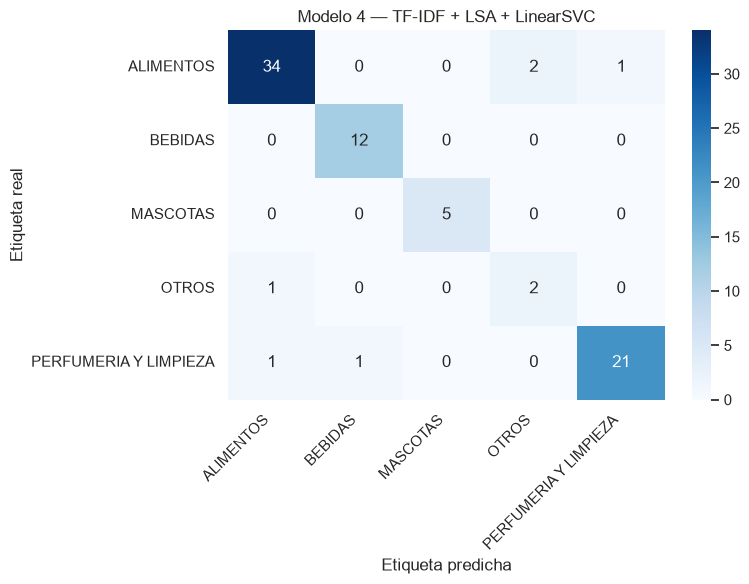

In [55]:
# Recuperamos las clases del clasificador final del pipeline
clases_modelo_4 = modelo_4.named_steps['svm'].classes_

cm_4 = confusion_matrix(y_test, y_pred_4, labels=clases_modelo_4)
plot_confusion_matrix(
    cm_4, clases_modelo_4,
    'Modelo 4 — TF-IDF + LSA + LinearSVC'
)

**Comentario del Modelo 4**

Con el mismo split y el mismo clasificador que el Modelo 2, la única diferencia es la representación: TF-IDF comprimido a 100 componentes latentes. El accuracy es el mismo (0,93). El macro F1 es 0,88, algo mayor que el del Modelo 2 (0,86) y menor que el del Modelo 1 (0,91). El weighted F1 (0,93) es el más alto de los cuatro, pero por poco sobre el Modelo 1.

En OTROS el modelo acierta 2 de 3 (recall 0,67), pero su precisión baja a 0,50 porque clasifica como OTROS a dos productos de ALIMENTOS. Estas diferencias equivalen a uno o dos productos del test. La conclusión es que LSA no aporta una mejora clara frente a TF-IDF directo, con un costo adicional (un paso más en el pipeline) que no se justifica con estos datos.

No se probaron otros valores de n_components (por ejemplo 30 o 50), por lo que esto queda como limitación.

## 11. Modelo 5, TF-IDF (palabras + caracteres) + LinearSVC

El quinto modelo mantiene el clasificador del Modelo 2 (LinearSVC con class_weight='balanced') y modifica únicamente la representación del texto. Además del TF-IDF de palabras (unigramas y bigramas) incorpora un TF-IDF de n-gramas de caracteres (analyzer='char_wb', de 2 a 5 caracteres), y concatena ambas representaciones.

¿Por qué probarlo? Las descripciones de los productos están abreviadas, truncadas y escritas de forma distinta en cada cadena (por ejemplo “CREM FACIAL CUID NUT”, “ANTITRANS” y “ANTITRANSP”, “X 750 CC”). Con TF-IDF de palabras, cada variante es un término distinto y sin relación con las demás. Los n-gramas de caracteres descomponen cada palabra en fragmentos solapados, de modo que palabras truncadas o abreviadas comparten señal. Las palabras completas aportan el significado exacto y los caracteres aportan robustez ante abreviaturas y variantes de escritura.

**Parámetros configurados:**

- Palabras: `ngram_range=(1, 2)`.
- Caracteres: `analyzer='char_wb'`, `ngram_range=(2, 5)`, `min_df=2`, que descarta fragmentos presentes en un solo documento.
- `sublinear_tf=True` en ambos: aplica una escala logarítmica a las frecuencias, para que una palabra repetida muchas veces no domine el vector.
- `LinearSVC(class_weight='balanced', max_iter=10000)`: mismo clasificador y misma compensación del desbalance que el Modelo 2, para aislar el efecto de la representación.

El modelo se construye como Pipeline: recibe el texto crudo y ajusta los vectorizadores solo con el conjunto de entrenamiento, sin data leakage.

Costo: bajo. Sigue siendo un modelo lineal sobre matrices ralas. Aunque el número de variables es mayor que en el Modelo 2, se espera un entrenamiento de segundos y sin GPU (no se midieron tiempos).

Nota metodológica: este enfoque se incorporó después de observar los resultados de los Modelos 1 a 4. Se evaluaron además otras variantes en una exploración preliminar y se retuvo la de mejor desempeño, por lo que su ventaja podría estar levemente sobrestimada.

In [56]:
from sklearn.pipeline import make_pipeline, make_union

vec_palabras = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
vec_caracteres = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True)

modelo_5 = make_pipeline(make_union(vec_palabras, vec_caracteres),
    LinearSVC(class_weight='balanced', max_iter=10000, random_state=RANDOM_STATE))

modelo_5.fit(X_train, y_train)
y_pred_5 = modelo_5.predict(X_test)

print("\n=== Modelo 5: TF-IDF (palabras + caracteres) + LinearSVC ===")
print(classification_report(y_test, y_pred_5))


=== Modelo 5: TF-IDF (palabras + caracteres) + LinearSVC ===
                       precision    recall  f1-score   support

            ALIMENTOS       0.93      1.00      0.96        37
              BEBIDAS       1.00      1.00      1.00        12
             MASCOTAS       1.00      1.00      1.00         5
                OTROS       1.00      0.33      0.50         3
PERFUMERIA Y LIMPIEZA       1.00      0.96      0.98        23

             accuracy                           0.96        80
            macro avg       0.98      0.86      0.89        80
         weighted avg       0.97      0.96      0.96        80



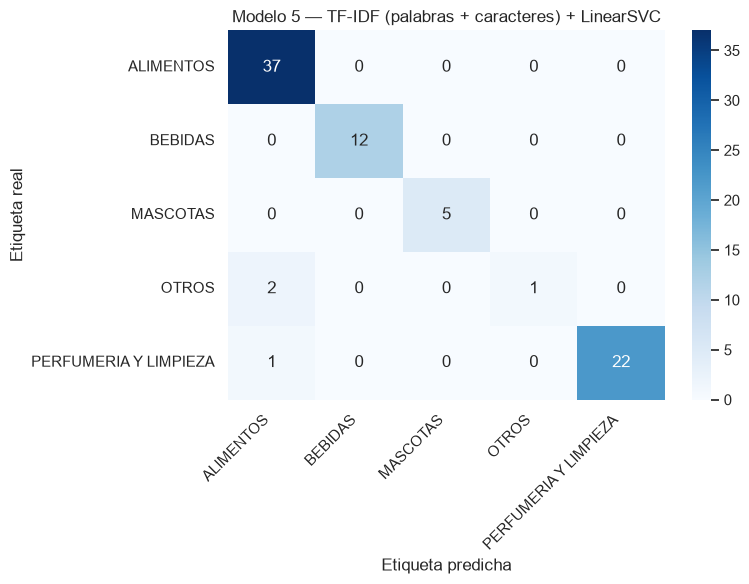

In [57]:
# Matriz de confusión
cm_5 = confusion_matrix(y_test, y_pred_5, labels=modelo_5.classes_)
plot_confusion_matrix(cm_5, modelo_5.classes_, 'Modelo 5 — TF-IDF (palabras + caracteres) + LinearSVC')

**Comentario del Modelo 5**

El modelo obtiene un accuracy de 0,96 (77 de 80 productos), el más alto de los cinco, y un weighted F1 de 0,96. Comete solo 3 errores: 2 productos de OTROS predichos como ALIMENTOS y 1 de PERFUMERIA Y LIMPIEZA predicho como ALIMENTOS. BEBIDAS y MASCOTAS alcanzan un F1 de 1,00, y ALIMENTOS y PERFUMERIA Y LIMPIEZA superan 0,96. Desaparecen los errores del Modelo 1 en los que productos líquidos de limpieza se predecían como BEBIDAS.

Sin embargo, su macro F1 es 0,89, menor que el del Modelo 1 (0,91). La diferencia se debe exclusivamente a OTROS: el modelo acierta solo 1 de los 3 productos (recall 0,33, F1 0,50), mientras que el Modelo 1 acertó 2 de 3. Con tres observaciones, un único producto explica esa diferencia, por lo que el test de 80 productos no permite concluir cuál de los dos modelos es mejor en macro F1. Esa pregunta se aborda con validación cruzada repetida en la sección 13.

## 12. Comparación final de modelos

Se consolidan las métricas de los cinco modelos sobre el mismo conjunto de test en una tabla única y luego se visualizan. Recordá que este test contiene solo 80 productos (3 de OTROS), por lo que las diferencias pequeñas deben leerse con cautela. La sección 13 complementa esta comparación con validación cruzada.

In [58]:
resultados = []
for nombre, y_pred in [
    ('Modelo 1: LogReg + TF-IDF', y_pred_1),
    ('Modelo 2: LinearSVC + TF-IDF', y_pred_2),
    ('Modelo 3: Doc2Vec + XGBoost', y_pred_3),
    ('Modelo 4: TF-IDF + LSA + LinearSVC', y_pred_4),
    ('Modelo 5: TF-IDF (palabras + caracteres) + LinearSVC', y_pred_5),
]:
    metricas = resumen_metricas(y_test, y_pred)
    metricas['Modelo'] = nombre
    resultados.append(metricas)

df_resultados = pd.DataFrame(resultados)[['Modelo', 'Accuracy', 'Macro F1', 'Weighted F1']]
df_resultados = df_resultados.round(4)
df_resultados

,Modelo,Accuracy,Macro F1,Weighted F1
0,Modelo 1: LogReg + TF-IDF,0.9250,0.9065,0.9239
1,Modelo 2: LinearSVC + TF-IDF,0.9250,0.8559,0.9192
2,Modelo 3: Doc2Vec + XGBoost,0.7750,0.7085,0.7676
3,Modelo 4: TF-IDF + LSA + LinearSVC,0.9250,0.8793,0.9271
4,Modelo 5: TF-IDF (palabras + caracteres) + Lin...,0.9625,0.8878,0.9568


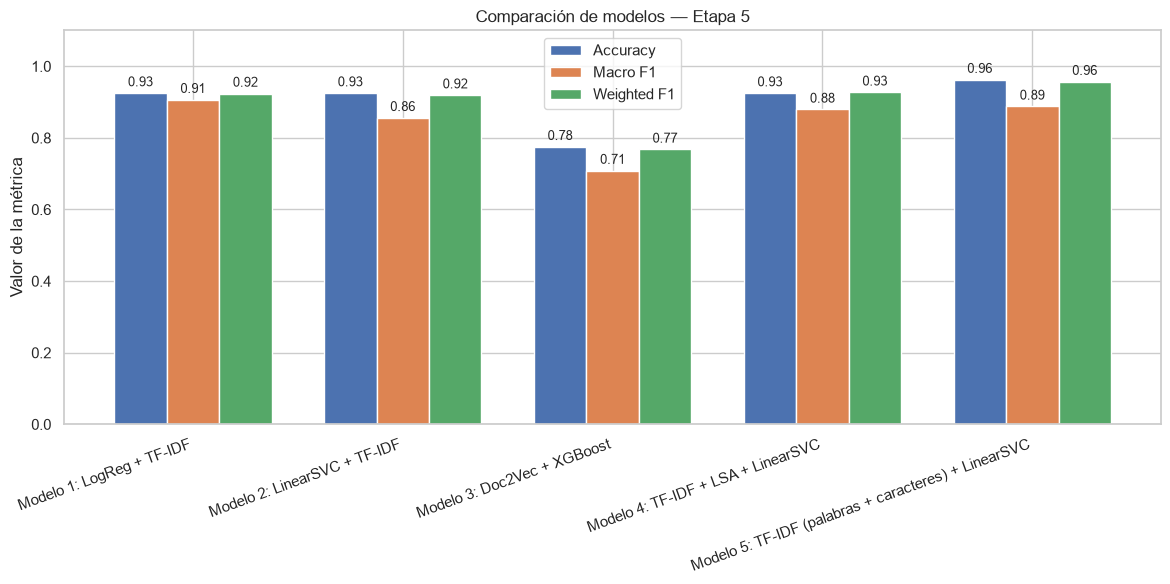

In [59]:
fig, ax = plt.subplots(figsize=(12, 6))

metricas = ['Accuracy', 'Macro F1', 'Weighted F1']
colores = ['#4c72b0', '#dd8452', '#55a868']
x = np.arange(len(df_resultados))
width = 0.25

for i, metrica in enumerate(metricas):
    posiciones = x + (i - 1) * width
    barras = ax.bar(posiciones, df_resultados[metrica], width, label=metrica, color=colores[i])
    ax.bar_label(barras, fmt='%.2f', padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(df_resultados['Modelo'], rotation=20, ha='right')
ax.set_ylabel('Valor de la métrica')
ax.set_ylim(0, 1.10)
ax.set_title('Comparación de modelos — Etapa 5')
ax.legend()

plt.tight_layout()
plt.show()

## 13. Validación cruzada repetida

La comparación de la sección 12 depende de un único split con un test de 80 productos, donde la categoría OTROS tiene solo 3 observaciones. Con tan pocos casos, un solo producto altera el ranking en macro F1. Para obtener una estimación más estable se utiliza validación cruzada estratificada de 5 folds repetida 3 veces (15 evaluaciones) sobre los 400 productos etiquetados.

Los vectorizadores se incluyen dentro de un Pipeline, de modo que en cada fold se ajustan solo con los datos de entrenamiento de ese fold (sin data leakage). Se comparan los Modelos 1, 2, 4 y 5. El Modelo 3 (Doc2Vec + XGBoost) se excluye porque su desempeño en test fue inferior y su costo es el mayor.

In [60]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

vec_m1 = lambda: TfidfVectorizer(max_features=20000, ngram_range=(1, 3), min_df=2, lowercase=True)
vec_m5 = lambda: make_union(
    TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
    TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True)
)

modelos_cv = {
    'Modelo 1: LogReg + TF-IDF': make_pipeline(
        vec_m1(), LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    'Modelo 2: LinearSVC + TF-IDF': make_pipeline(
        vec_m1(), LinearSVC(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE)),
    'Modelo 4: TF-IDF + LSA + LinearSVC': make_pipeline(
        vec_m1(), TruncatedSVD(n_components=100, random_state=RANDOM_STATE),
        LinearSVC(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE)),
    'Modelo 5: TF-IDF (palabras + caracteres) + LinearSVC': make_pipeline(
        vec_m5(), LinearSVC(class_weight='balanced', max_iter=10000, random_state=RANDOM_STATE)),
}

resultados_cv, filas = {}, []
for nombre, pipe in modelos_cv.items():
    s = cross_validate(pipe, X, y, cv=cv_rep,
                       scoring=['accuracy', 'f1_macro', 'f1_weighted'], n_jobs=-1)
    resultados_cv[nombre] = s
    filas.append({
        'Modelo': nombre,
        'Accuracy': s['test_accuracy'].mean(),
        'Macro F1': s['test_f1_macro'].mean(),
        'Desvío Macro F1': s['test_f1_macro'].std(),
        'Weighted F1': s['test_f1_weighted'].mean(),
    })

df_cv = pd.DataFrame(filas).sort_values('Macro F1', ascending=False).round(3)
df_cv

,Modelo,Accuracy,Macro F1,Desvío Macro F1,Weighted F1
3,Modelo 5: TF-IDF (palabras + caracteres) + Lin...,0.947,0.911,0.061,0.944
1,Modelo 2: LinearSVC + TF-IDF,0.907,0.858,0.049,0.904
2,Modelo 4: TF-IDF + LSA + LinearSVC,0.898,0.849,0.051,0.895
0,Modelo 1: LogReg + TF-IDF,0.896,0.847,0.059,0.893


In [61]:
ref = 'Modelo 5: TF-IDF (palabras + caracteres) + LinearSVC'
for nombre, s in resultados_cv.items():
    if nombre == ref:
        continue
    dif = resultados_cv[ref]['test_f1_macro'] - s['test_f1_macro']
    print(f"Modelo 5 vs {nombre}: dif. media de macro F1 = {dif.mean():+.4f} | "
          f"gana en {(dif > 0).sum()}/15 folds, empata {(dif == 0).sum()}, pierde {(dif < 0).sum()}")

Modelo 5 vs Modelo 1: LogReg + TF-IDF: dif. media de macro F1 = +0.0643 | gana en 13/15 folds, empata 0, pierde 2
Modelo 5 vs Modelo 2: LinearSVC + TF-IDF: dif. media de macro F1 = +0.0528 | gana en 13/15 folds, empata 1, pierde 1
Modelo 5 vs Modelo 4: TF-IDF + LSA + LinearSVC: dif. media de macro F1 = +0.0627 | gana en 13/15 folds, empata 0, pierde 2


**Lectura de la validación cruzada**

Con 15 evaluaciones sobre los 400 productos, el Modelo 5 obtiene el mejor desempeño en las tres métricas (accuracy 0,947; macro F1 0,911; weighted F1 0,944). Supera al Modelo 1 en 0,064 puntos de macro F1 y le gana en 13 de los 15 folds. Los Modelos 1, 2 y 4 quedan agrupados entre 0,85 y 0,86 de macro F1, de modo que, a diferencia del test, la validación cruzada no los distingue claramente entre sí.

El desvío entre folds (cerca de 0,06) indica que el macro F1 varía bastante según la partición, por lo que la ventaja del Modelo 5 debe interpretarse como consistente pero moderada, y no como una diferencia exacta. Además, las estimaciones de validación cruzada difieren de las del test en ambos sentidos: son más bajas para los Modelos 1 y 4, similares para el Modelo 2 y más altas para el Modelo 5. Esto confirma que el test de 80 productos es una referencia ruidosa.

## 14. Conclusiones metodológicas

### 14.1 Modelo ganador

El Modelo 5 (TF-IDF de palabras + caracteres + LinearSVC, balanceado) es el modelo seleccionado. En el split de test obtuvo el mayor accuracy (0,96) y el mayor weighted F1 (0,96), pero un macro F1 (0,89) algo inferior al del Modelo 1 (0,91), diferencia que se explica por un único producto de la categoría OTROS (3 en test). Dado que el macro F1 del test no permite distinguir entre modelos con tan pocas observaciones en esa categoría, la decisión se apoya en la validación cruzada repetida (sección 13), donde el Modelo 5 obtuvo el mejor macro F1 (0,911 contra 0,847 del Modelo 1) y le ganó en 13 de 15 folds.

Cabe aclarar que el uso de la validación cruzada como criterio de selección se incorporó después de observar los resultados del test. El modelo mantiene la complejidad de un clasificador lineal, con costo computacional bajo.

---

### 14.2 Equilibrio entre el rendimiento de las clases mayoritarias y minoritarias

- Los Modelos 1, 2, 4 y 5 usan class_weight='balanced' por el desbalance detectado en la sección 3 (el Modelo 3 no).
- OTROS es la categoría más sensible: con 3 productos en test, un solo error mueve su recall 33 puntos porcentuales y su F1 varía entre 0,50 y 0,80 según el modelo. Es además una categoría residual y heterogénea (pilas, bolsas, juguetes, una bombilla), lo que dificulta que cualquier modelo aprenda un patrón.
- Las demás categorías tienen F1 altos con los modelos TF-IDF. El Modelo 5 resuelve los errores del Modelo 1 en los que productos líquidos de limpieza se predecían como BEBIDAS.

---

### 14.3 ¿Vale la pena Doc2Vec + XGBoost en este punto del proyecto?

Con el tamaño actual del corpus etiquetado, Doc2Vec + XGBoost no resulta la alternativa más conveniente. El Modelo 3 obtuvo un accuracy de 0,78 y un Macro F1 de 0,71, mostrando un rendimiento inferior al de los demás modelos evaluados y una mayor complejidad computacional.

Con 320 documentos de entrenamiento, la representación generada por Doc2Vec no logró superar los resultados obtenidos mediante TF-IDF. Una posible explicación es el tamaño reducido del corpus, que puede limitar el aprendizaje de representaciones eficaces. Además, la ausencia de balanceo de clases podría influir en las dificultades observadas en categorías minoritarias, especialmente OTROS.

Por lo tanto, **se decide excluir el Modelo 3 de la validación cruzada posterior**, priorizando los enfoques que demostraron mejores resultados y menor complejidad. Además, Doc2Vec requirió controles adicionales para garantizar la reproducibilidad de sus resultados. Sería interesante volver a evaluar Doc2Vec + XGBoost si el corpus de entrenamiento crece considerablemente.

---

### 14.4 Limitaciones

- El conjunto etiquetado (400 productos) es reducido y el test tiene 80, con solo 3 de OTROS: una diferencia de un producto cambia el ranking en macro F1.
- El Modelo 5 se incorporó y se eligió después de observar los resultados de los otros modelos, y entre varias variantes exploradas, por lo que su ventaja puede estar levemente sobrestimada.
- La validación cruzada no incluyó el Modelo 3.
- No se realizó una comparación controlada de cada clasificador con y sin balanceo de clases, por lo que no se pudo medir el efecto específico de este parámetro sobre el rendimiento.
- No se midieron tiempos de entrenamiento: el costo se describe de forma cualitativa.
- La tokenización de Doc2Vec es simple (regex y minúsculas), sin lematización.
- El etiquetado manual no es una muestra aleatoria: se priorizó incluir ejemplos de MASCOTAS y OTROS para equilibrar el entrenamiento. Por eso la distribución del conjunto etiquetado difiere de la del universo completo, y la precisión medida en test para estas categorías puede ser optimista respecto de su desempeño sobre la población real. Además, el modelo predice solo 1 producto como OTROS entre los 1.820; esto es coherente con el etiquetado dirigido, pero no puede descartarse cierta subpredicción (recall de OTROS en test: 0,33).
- La división aleatoria entre entrenamiento y prueba no controla explícitamente la presencia de productos muy similares o variantes de una misma familia comercial en ambos conjuntos. Por lo tanto, las métricas podrían resultar optimistas respecto del desempeño sobre productos con características significativamente distintas de las observadas durante el entrenamiento.


## 15. Aplicación del modelo ganador a los productos sin etiquetar

Con el modelo seleccionado (Modelo 5), se predice la categoría de los productos que aún no tienen etiqueta manual. Dado que la elección se apoyó en la validación cruzada sobre los 400 productos, el modelo final se reentrena con todos los productos etiquetados antes de predecir (el Pipeline ajusta sus vectorizadores solo con esos datos). Como consecuencia, estas predicciones no pueden evaluarse con métricas, ya que los 1.820 productos no tienen etiqueta real.

Una vez obtenidas las predicciones, se realizará una auditoría exploratoria para detectar posibles errores de clasificación. Posteriormente, las categorías predichas se integrarán con las etiquetas manuales originales y los precios medios de ambas cadenas, generando un único dataset en formato Parquet para utilizar en la Etapa 6.

In [62]:
from sklearn.base import clone

# Modelo ganador: Modelo 5. Se reentrena con los 400 productos etiquetados
# (el Pipeline ajusta sus vectorizadores solo con esos datos)
modelo_ganador = clone(modelo_5).fit(X, y)

# Filtramos productos sin categoría
productos_sin_etiqueta = productos_etiquetados_parcialmente[
    productos_etiquetados_parcialmente['categoria'].isna()
].copy()

# Construimos el mismo texto combinado utilizado en entrenamiento
productos_sin_etiqueta['texto_combinado'] = (
    productos_sin_etiqueta['descripcion_carrefour'].fillna('') + ' ' +
    productos_sin_etiqueta['descripcion_dia'].fillna('') + ' ' +
    productos_sin_etiqueta['productos_marca'].fillna('')
)

# Predecimos (el Pipeline vectoriza internamente con lo aprendido en el fit)
productos_sin_etiqueta['categoria_predicha'] = modelo_ganador.predict(
    productos_sin_etiqueta['texto_combinado']
)

print(f"Productos categorizados automáticamente: {len(productos_sin_etiqueta)}")

# Distribución de categorías predichas: cantidad y porcentaje
conteo_predicho = productos_sin_etiqueta['categoria_predicha'].value_counts()
porcentaje_predicho = (conteo_predicho / conteo_predicho.sum() * 100).round(2)

distribucion_predicha = pd.DataFrame({
    'Cantidad': conteo_predicho,
    'Porcentaje (%)': porcentaje_predicho
})
distribucion_predicha.index.name = 'Categoría predicha'

print("\nDistribución de categorías predichas:")
distribucion_predicha

Productos categorizados automáticamente: 1820

Distribución de categorías predichas:


,Cantidad,Porcentaje (%)
Categoría predicha,,
ALIMENTOS,892,49.01
PERFUMERIA Y LIMPIEZA,598,32.86
BEBIDAS,318,17.47
MASCOTAS,11,0.60
OTROS,1,0.05


In [63]:
# Auditoría: productos sin etiqueta con mayor puntaje para cada categoría minoritaria
puntajes = modelo_ganador.decision_function(productos_sin_etiqueta['texto_combinado'])
clases = list(modelo_ganador.classes_)

for cat in ['MASCOTAS', 'OTROS']:
    productos_sin_etiqueta['puntaje'] = puntajes[:, clases.index(cat)]
    print(f"\nTop 15 de productos sin etiqueta con mayor puntaje para {cat}:")
    display(
        productos_sin_etiqueta
        .sort_values('puntaje', ascending=False)
        [['descripcion_carrefour', 'categoria_predicha', 'puntaje']]
        .head(15).round(2)
    )

productos_sin_etiqueta = productos_sin_etiqueta.drop(columns='puntaje')


Top 15 de productos sin etiqueta con mayor puntaje para MASCOTAS:


,descripcion_carrefour,categoria_predicha,puntaje
2170,ALIMENTO GATOS CAT CHOW ADULTO CARNE POLLO 0.5 K,MASCOTAS,1.12
240,ALIMENTOS PERROS DOGUI ADULTOS 3KG,MASCOTAS,1.07
2192,ALIMENTO PERROS DOG CHOW CACH.G.COMIENZO RPQ 1.5K,MASCOTAS,1.01
2182,ALIMENTO GATOS GATI CARNE Y POLLO 3KG,MASCOTAS,0.99
2173,ALIMENTO GATOS CAT CHOW GATITOS PESCADO CARNE ...,MASCOTAS,0.99
2189,ALIMENTO PERROS DOG CHOW CACHORRO G.COMIENZO 1.5K,MASCOTAS,0.98
2194,DOG CHOW M L TRIPLE PROTEIN 8 KG AR,MASCOTAS,0.94
2172,ALIMENTO GATOS CAT CHOW ADULTO CARNE POLLO 3 K,MASCOTAS,0.94
2174,ALIMENTO GATOS CAT CHOW ESTERILIZADOS PESCADO ...,MASCOTAS,0.92
2197,DOG CHOW MINI SML TRIPLE PROTEIN 6 X 3 KG AR,MASCOTAS,0.91



Top 15 de productos sin etiqueta con mayor puntaje para OTROS:


,descripcion_carrefour,categoria_predicha,puntaje
1969,BOLSA AFA FRISELINA PLANA SURTIDA 45X39X10 CM,OTROS,0.27
942,PALITOS PARA BROCHETTE IDEAL 20 CM X 25 UNI,ALIMENTOS,-0.40
1642,FIBRA ESPONJA MORTIMER LISA,PERFUMERIA Y LIMPIEZA,-0.41
1643,ESPONJA PODEROSA C FIBRA MORTIMER X 1 UN,PERFUMERIA Y LIMPIEZA,-0.45
1859,KIT DE LIMPIEZA HANTS 5 PIEZAS GRIS,ALIMENTOS,-0.45
1586,MINI MERENGUE MUNDIAL X 100 GRS,ALIMENTOS,-0.63
1768,ROLLITO INOXY VIRULANA X 1 UNI,PERFUMERIA Y LIMPIEZA,-0.69
1875,BISCUIT BOLSA CRISTAL X 142 GRS,ALIMENTOS,-0.71
2045,BEBIDA ENERGIZ MONSTER ZERO LATA X473,BEBIDAS,-0.73
1035,ARROZ DOBLE CAROLINA MOLINOS ALA BOLSA X 1 KG,ALIMENTOS,-0.73


**Lectura de las predicciones**

En las predicciones sobre los 1.820 productos, ALIMENTOS concentra el 49,01 %, PERFUMERIA Y LIMPIEZA el 32,86 % y BEBIDAS el 17,47 %. MASCOTAS (11 productos, 0,60 %) y OTROS (1 producto, 0,05 %) quedan muy por debajo de su peso en el conjunto etiquetado (6,75 % y 3 %).

Una explicación probable es el etiquetado dirigido: al etiquetar manualmente los 400 productos se buscó incluir deliberadamente más ejemplos de MASCOTAS y OTROS para equilibrar el entrenamiento, por lo que esos productos quedaron mayormente en el conjunto etiquetado y quedan pocos entre los 1.820 sin etiqueta. La auditoría de los productos con mayor puntaje respalda esta explicación para MASCOTAS: los 11 predichos son alimentos para perros y gatos, y el siguiente candidato tiene un puntaje claramente negativo. Para OTROS, solo un producto tiene puntaje positivo y los siguientes candidatos son ambiguos (esponjas, un kit de limpieza, palitos para brochette), con al menos dos casos que el modelo clasificó como ALIMENTOS y que probablemente correspondan a otra categoría.

Esta explicación no excluye que el modelo subpredica OTROS, ya que su recall en test fue 0,33 (1 de 3 productos). Como los 1.820 productos no tienen etiqueta real, no puede evaluarse con métricas. La baja frecuencia de predicciones de OTROS motivó una revisión manual de los productos con mayor puntaje de decisión para esa categoría. Esta inspección permitió detectar dos errores de clasificación, documentados y corregidos en la sección 15.1.

### 15.1 Auditoría manual y corrección de predicciones

Una vez clasificadas automáticamente las 1.820 observaciones sin etiqueta manual, se realizó una auditoría exploratoria para identificar posibles errores antes de consolidar el dataset definitivo.

La revisión se concentró en dos aspectos:

- **Categorías minoritarias:** se inspeccionaron los productos con mayor puntaje de decisión para MASCOTAS y OTROS, así como los 12 productos efectivamente predichos en estas categorías.
- **Categorías mayoritarias:** se seleccionó una muestra aleatoria reproducible de 15 productos por categoría (ALIMENTOS, BEBIDAS y PERFUMERIA Y LIMPIEZA), utilizando `random_state=42`.

El objetivo fue contrastar las predicciones con las descripciones comerciales y las reglas de clasificación establecidas en la Etapa 4. Esta revisión complementa las métricas del conjunto de prueba, pero no constituye una validación exhaustiva de las 1.820 predicciones.

Durante la inspección de los productos con mayor puntaje para OTROS se identificaron dos clasificaciones incorrectas:

| Producto | Categoría predicha | Categoría corregida |
|---|---|---|
| PALITOS PARA BROCHETTE IDEAL 20 CM X 25 UNI | ALIMENTOS | OTROS |
| KIT DE LIMPIEZA HANTS 5 PIEZAS GRIS | ALIMENTOS | PERFUMERIA Y LIMPIEZA |

Las correcciones se aplicaron manualmente sobre `categoria_final`, conservando `categoria_predicha` para mantener la trazabilidad de las decisiones del modelo.

Estas modificaciones no alteran el entrenamiento ni las métricas de evaluación previamente obtenidas.

In [64]:
# Correcciones identificadas durante la auditoría manual 
# de los top 15 productos sin etiqueta con mayor puntaje para MASCOTAS y OTROS
# Verificamos los productos que requieren corrección para ver su id_producto
productos_sin_etiqueta.loc[
    [942, 1859],
    ['id_producto', 'descripcion_carrefour', 'categoria_predicha']
]

,id_producto,descripcion_carrefour,categoria_predicha
942,7790773034502,PALITOS PARA BROCHETTE IDEAL 20 CM X 25 UNI,ALIMENTOS
1859,7797196045450,KIT DE LIMPIEZA HANTS 5 PIEZAS GRIS,ALIMENTOS


In [65]:
# Realizamos las correcciones identificadas por su id_producto (se aplicarán a la columna 'categoria_final')
correcciones_manuales = {
    '7790773034502': 'OTROS',
    '7797196045450': 'PERFUMERIA Y LIMPIEZA'
}

# Conservamos las predicciones originales del modelo
productos_sin_etiqueta['categoria_final'] = (productos_sin_etiqueta['categoria_predicha'].copy())

# Aplicamos las correcciones utilizando id_producto
ids = productos_sin_etiqueta['id_producto'].astype(str)

assert set(correcciones_manuales).issubset(set(ids))

productos_sin_etiqueta['categoria_final'] = (ids.map(correcciones_manuales).fillna(productos_sin_etiqueta['categoria_predicha']))

# Verificamos los productos corregidos
display(
    productos_sin_etiqueta.loc[ids.isin(correcciones_manuales),['id_producto', 'descripcion_carrefour','categoria_predicha', 'categoria_final']]
)

,id_producto,descripcion_carrefour,categoria_predicha,categoria_final
942,7790773034502,PALITOS PARA BROCHETTE IDEAL 20 CM X 25 UNI,ALIMENTOS,OTROS
1859,7797196045450,KIT DE LIMPIEZA HANTS 5 PIEZAS GRIS,ALIMENTOS,PERFUMERIA Y LIMPIEZA


In [66]:
# Auditoría: revisión de productos con categorías minoritarias
categorias_minoritarias = ['MASCOTAS', 'OTROS']

revision_minoritarias = productos_sin_etiqueta[productos_sin_etiqueta['categoria_predicha'].isin(categorias_minoritarias)]

display(
    revision_minoritarias[['id_producto', 'descripcion_carrefour','categoria_predicha', 'categoria_final']]
)

,id_producto,descripcion_carrefour,categoria_predicha,categoria_final
240,7613287613431,ALIMENTOS PERROS DOGUI ADULTOS 3KG,MASCOTAS,MASCOTAS
1969,7798160469616,BOLSA AFA FRISELINA PLANA SURTIDA 45X39X10 CM,OTROS,OTROS
2063,7891000241080,ALIMENTO GATOS HUMEDO FELIX POUCH SALMON 85GRS,MASCOTAS,MASCOTAS
2170,8445290068507,ALIMENTO GATOS CAT CHOW ADULTO CARNE POLLO 0.5 K,MASCOTAS,MASCOTAS
2172,8445290068705,ALIMENTO GATOS CAT CHOW ADULTO CARNE POLLO 3 K,MASCOTAS,MASCOTAS
2173,8445290069313,ALIMENTO GATOS CAT CHOW GATITOS PESCADO CARNE ...,MASCOTAS,MASCOTAS
2174,8445290070647,ALIMENTO GATOS CAT CHOW ESTERILIZADOS PESCADO ...,MASCOTAS,MASCOTAS
2182,8445290585042,ALIMENTO GATOS GATI CARNE Y POLLO 3KG,MASCOTAS,MASCOTAS
2189,8445290944184,ALIMENTO PERROS DOG CHOW CACHORRO G.COMIENZO 1.5K,MASCOTAS,MASCOTAS
2192,8445290944801,ALIMENTO PERROS DOG CHOW CACH.G.COMIENZO RPQ 1.5K,MASCOTAS,MASCOTAS


Se inspeccionaron los 11 productos predichos como MASCOTAS y el único producto predicho como OTROS.

Los 11 productos de MASCOTAS corresponden a alimentos para perros y gatos, mientras que el producto de OTROS es una bolsa de friselina. En los 12 casos, las categorías predichas resultaron coherentes con las descripciones comerciales y los criterios definidos en la Etapa 4.

Sin embargo, esta revisión solo permite evaluar los productos que el modelo asignó a dichas categorías. No permite descartar que existan productos pertenecientes a MASCOTAS u OTROS clasificados incorrectamente dentro de las categorías mayoritarias.

De hecho, durante la inspección de candidatos con alto puntaje relativo para OTROS ya se habían detectado dos errores que requirieron corrección manual.

In [67]:
# Auditoría: revisión de productos con categorías mayoritarias
categorias_mayoritarias = [
    'ALIMENTOS',
    'BEBIDAS',
    'PERFUMERIA Y LIMPIEZA'
]

for categoria in categorias_mayoritarias:
    print(f'\nRevisión de {categoria}')

    muestra = productos_sin_etiqueta[productos_sin_etiqueta['categoria_predicha'] == categoria].sample(n=15, random_state=RANDOM_STATE)

    display(
        muestra[['id_producto', 'descripcion_carrefour','categoria_predicha', 'categoria_final']]
    )


Revisión de ALIMENTOS


,id_producto,descripcion_carrefour,categoria_predicha,categoria_final
1761,7794000009547,PASTA MAC AND CHEESE KNORR X 200 GRS,ALIMENTOS,ALIMENTOS
1299,7791337008588,YOGUR COLCHON FRUTILLA DULCE SER X170 GRS,ALIMENTOS,ALIMENTOS
1404,7791675909578,ACEITUNAS VERDES RELLENAS CASTELL DOY PACK X12...,ALIMENTOS,ALIMENTOS
1793,7794600004539,GALLETITAS CHOCOLATE RELL LIMON MELBA 3 X120 GRS,ALIMENTOS,ALIMENTOS
348,7790040133471,GALLETITAS FRAMBUESA RELL FRUTI SONRISAS 3 X 1...,ALIMENTOS,ALIMENTOS
810,7790538010437,NACHOS REDONDOS MAIZ BLANCO MACRITAS X 200 GRS,ALIMENTOS,ALIMENTOS
825,7790580131470,BANO REPOSTERIA CHOC CON LECHE AGUILA X 150 GRS,ALIMENTOS,ALIMENTOS
875,7790670052371,MEDALLON DE CARNE EXPRESS PATY CAJA X 4 UNI,ALIMENTOS,ALIMENTOS
604,7790199602927,PAN RALLADO MORIXE PAQUETE X 1KG,ALIMENTOS,ALIMENTOS
477,7790070433145,ARROZ LARGO FINO 00000 GALLO BOLSA X 500 GRS,ALIMENTOS,ALIMENTOS



Revisión de BEBIDAS


,id_producto,descripcion_carrefour,categoria_predicha,categoria_final
956,7790895000232,GASEOSA COLA REGULAR COCA COLA LATA X 354 CC.,BEBIDAS,BEBIDAS
1925,7798108834377,VINO TINTO SYRAH MALBEC CALLIA ESPERADO X 750 CC,BEBIDAS,BEBIDAS
518,7790070760821,VINO TINTO MALBEC NIETO SENETINER BOT X 750 CC,BEBIDAS,BEBIDAS
1899,7798062548648,AGUA SABORIZADA NARANJA S GAS VDS LEVITE X 1.5 LT,BEBIDAS,BEBIDAS
261,7622201735340,JUGO EN POLVO NARANJA DULCE TANG X 15 GRS,BEBIDAS,BEBIDAS
989,7790950001969,APERITIVO C ALC TINTO AMARGO OBRERO X 950 CC,BEBIDAS,BEBIDAS
1435,7791843008294,VINO TINTO BORGONA VINAS DE BALBO X 1125 CC.,BEBIDAS,BEBIDAS
1457,7792170052271,ISOTONICA MANZANA GATORADE PET X 750 CC,BEBIDAS,BEBIDAS
702,7790314079924,VINO TINTO BLEND III CANCILLER BOT X 750 CC,BEBIDAS,BEBIDAS
1005,7790950147926,APERTIVO SIN ALC AMERICANO 0% GANCIA LATA X 47...,BEBIDAS,BEBIDAS



Revisión de PERFUMERIA Y LIMPIEZA


,id_producto,descripcion_carrefour,categoria_predicha,categoria_final
180,7509546686042,CREMA DENTAL CARBON ACT TOTAL 12 COLGATE X 90 GRS,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
1128,7791290794276,LAVAVAJILLA CONCENT LIMON ALA BOTELLA X 300 CC,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
2114,7891040142712,FIBRA NO RAYA SCOTCH BRITE X 1 UNI,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
136,7500435243667,MASCARILLA CAPILAR NUTRICION PANTENE X 270 CC,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
333,7790033338203,SHAMPOO GLYCOLIC CRISTAL ELVIVE X 200 CC,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
1125,7791290794221,LIMPIADOR CREMOSO BIOACTIVE ORIGINAL CIF X 500 CC,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
44,190679000088,SHAMPOO ARGAN OIL HERBAL ESSENCES X 400 CC,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
1643,7793253092276,ESPONJA PODEROSA C FIBRA MORTIMER X 1 UN,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
138,7500435245852,MAQ DE AFEITAR PRESTOBARBA3 CARBONO GILLETTE X...,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA
1259,7791293050942,JABON DE TOCADOR FUTBOL FANATICS REXONA 3 X120...,PERFUMERIA Y LIMPIEZA,PERFUMERIA Y LIMPIEZA


Se revisaron 45 productos seleccionados aleatoriamente: 15 de ALIMENTOS, 15 de BEBIDAS y 15 de PERFUMERIA Y LIMPIEZA.

En las muestras inspeccionadas no se identificaron errores evidentes de clasificación. Las predicciones resultaron coherentes con las descripciones comerciales y con las reglas de la taxonomía definida.

Este resultado constituye una comprobación exploratoria favorable, aunque limitada por el tamaño de la muestra. No permite garantizar que todos los productos de estas categorías hayan sido clasificados correctamente.

**Balance de la auditoría:** se identificaron y corrigieron dos errores en la inspección de los candidatos a categorías minoritarias. No se observaron errores adicionales en los 12 productos predichos como MASCOTAS u OTROS ni en la muestra aleatoria de 45 productos de las categorías mayoritarias.

Con las correcciones incorporadas, se procede a consolidar las categorías manuales y automáticas para construir el dataset que utilizará la Etapa 6.

## 16. Consolidación y exportación del dataset categorizado

Finalizada la auditoría manual, se integran las categorías asignadas originalmente en la Etapa 4 con las predicciones generadas por el modelo ganador, incluyendo las correcciones realizadas en la sección 15.1.

El resultado reúne los **2.220 productos del universo principal de siete provincias**:

- 400 productos con categorías asignadas manualmente.
- 1.820 productos clasificados automáticamente, de los cuales dos recibieron correcciones manuales posteriores.

Para cada producto se conserva únicamente la información necesaria para continuar con la construcción de la canasta comparable:

| Columna | Descripción |
|---|---|
| `id_producto` | Identificador único del producto. |
| `descripcion_carrefour` | Descripción comercial del producto en Carrefour. |
| `precio_medio_carrefour` | Precio medio del producto en Carrefour, calculado en las etapas anteriores. |
| `precio_medio_dia` | Precio medio del producto en DIA, calculado en las etapas anteriores. |
| `categoria` | Categoría comercial definitiva, con las correcciones manuales incorporadas. |

La consolidación se realiza mediante `id_producto`, conservando el universo original de productos. Antes de exportar el resultado, se ejecutan controles de integridad para verificar:

1. Que el dataset contenga exactamente 2.220 registros.
2. Que cada identificador de producto sea único.
3. Que ningún producto tenga la categoría faltante.
4. Que los precios medios de ambas cadenas estén presentes.
5. Que todas las categorías asignadas pertenezcan a las cinco categorías comerciales definidas.

Una vez superados estos controles, el resultado se exporta en formato Parquet como:

`data/processed/productos_media_y_categorizados.parquet`

Este archivo constituye la salida definitiva de la Etapa 5 y será utilizado como entrada en la Etapa 6 para seleccionar los productos de la canasta y comparar sus precios entre DIA y Carrefour.

In [68]:
# Productos etiquetados manualmente
productos_manuales = productos_etiquetados_parcialmente[productos_etiquetados_parcialmente['categoria'].notna()][['id_producto', 'categoria']].copy()

# Productos clasificados automáticamente, con correcciones aplicadas
productos_modelo = productos_sin_etiqueta[['id_producto', 'categoria_final']].rename(columns={'categoria_final': 'categoria'})

# Unificamos las categorías
categorias_finales = pd.concat([productos_manuales, productos_modelo],ignore_index=True)

In [69]:
# Recuperamos las descripciones y los precios del dataset original
columnas = ['id_producto', 'descripcion_carrefour', 'precio_medio_carrefour', 'precio_medio_dia']

productos_categorizados = (productos_etiquetados_parcialmente[columnas].merge(categorias_finales, on='id_producto', how='left', validate='one_to_one'))


In [70]:
# Validaciones
assert len(productos_categorizados) == 2220
assert productos_categorizados['id_producto'].is_unique
assert productos_categorizados['categoria'].notna().all()
assert productos_categorizados[['precio_medio_carrefour', 'precio_medio_dia']].notna().all().all()

In [71]:
# Validación de categorías
categorias_validas = {'ALIMENTOS', 'BEBIDAS', 'MASCOTAS', 'OTROS', 'PERFUMERIA Y LIMPIEZA'}

assert productos_categorizados['categoria'].isin(categorias_validas).all()

In [72]:
# Guardamos el archivo definitivo para la Etapa 6
output_path = '../data/processed/productos_media_y_categorizados.parquet'

productos_categorizados.to_parquet(output_path, index=False)

print(f"Archivo guardado en: {output_path}")
print(f"Total de productos: {len(productos_categorizados)}")

display(productos_categorizados.head(10))

Archivo guardado en: ../data/processed/productos_media_y_categorizados.parquet
Total de productos: 2220


,id_producto,descripcion_carrefour,precio_medio_carrefour,precio_medio_dia,categoria
0,40084107,HUEVO CHOCOLATE SORPRESA CELESTE KINDER X 20 GRS,2875.50,2793.33,ALIMENTOS
1,42277057,CREMA FACIAL CUIDADO NUTRITIVO NIVEA CARE X 100CC,7872.42,6455.00,PERFUMERIA Y LIMPIEZA
2,75079437,ANTITRANSP FEM CREMA CLINICAL SOFT DOVE X 58GRS,18265.21,12750.00,PERFUMERIA Y LIMPIEZA
3,75082734,ANTITRANSPIRANTE BARRA ORIGINAL DOVE X 53 GR,7906.62,8037.19,PERFUMERIA Y LIMPIEZA
4,75083694,DESODORANTE STICK BLUE LAVENDER AXE X 58 GRM,8677.08,8718.77,PERFUMERIA Y LIMPIEZA
5,75083700,DESODORANTE STICK AQUA CITRUS AXE X 58 GRM,8677.08,8718.77,PERFUMERIA Y LIMPIEZA
6,77903785,ALFAJOR TRIPLE MILKA MOUSSE X 55 GRS.,2024.33,2000.00,ALIMENTOS
7,77903860,ALFAJOR TERRABUSI TORTA X 70 GRS,2111.71,2000.00,ALIMENTOS
8,77907943,CARAMELO MASTICABLE TUTTI FRUTTI LENGUETAZO X ...,395.24,450.00,ALIMENTOS
9,77908308,ALFAJOR CHOCOLATE TITA X 36 GRS,1006.30,970.00,ALIMENTOS


## Cierre de la Etapa 5

Se completó el flujo de clasificación automática de productos:

1. **Preparación y análisis** del conjunto etiquetado manualmente (400 productos).
2. **Preprocesamiento y vectorización** con TF-IDF ajustado exclusivamente sobre el conjunto de entrenamiento.
3. **Entrenamiento y evaluación** de cinco enfoques:
   - TF-IDF + LogisticRegression
   - TF-IDF + LinearSVC
   - Doc2Vec + XGBoost
   - TF-IDF + LSA + LinearSVC
   - TF-IDF (palabras + caracteres) + LinearSVC
4. **Selección del modelo ganador** (Modelo 5) con base en el Macro F1 de la validación cruzada repetida, utilizada para obtener una comparación más estable que la evaluación sobre un único conjunto de prueba de 80 productos.
5. **Aplicación del modelo ganador** sobre los 1.820 productos sin etiqueta manual.
6. **Auditoría exploratoria de las predicciones**, incluyendo revisión de categorías minoritarias y muestras aleatorias de las mayoritarias.
7. **Corrección manual de dos clasificaciones incorrectas**, conservando las predicciones originales del modelo.
8. **Consolidación y exportación** de los 2.220 productos en un único archivo Parquet, junto con sus descripciones, precios medios por cadena y categorías definitivas.

La clasificación automática permitió completar la categorización del universo principal sin necesidad de etiquetar manualmente todos los productos. Sin embargo, las métricas de evaluación y los controles exploratorios no garantizan la ausencia de errores en los productos no revisados.

El dataset resultante proporciona una base categorizada y validada mediante controles de integridad para avanzar hacia la construcción de la canasta comparable en la Etapa 6. Las categorías obtenidas mediante Machine Learning deben interpretarse teniendo en cuenta las limitaciones de la muestra de entrenamiento y de la auditoría realizada.

El resultado de esta etapa habilita la construcción de la canasta comparable y los análisis finales del proyecto, con una base documentada de productos clasificados y una justificación explícita de las decisiones metodológicas adoptadas.